# Researcher–author disambiguation

This walkthrough loads the shared synthetic pipeline configuration, calls the disambiguation computation API directly, and explores its returned objects. The synthetic researchers and publication records are fictitious. It does not persist disambiguation outputs.

## What the stage does

Name matching supplies candidate Scopus author profiles. Disambiguation scores profile pairs using name, publication, coauthor, citation, subject-area, and affiliation evidence; groups profiles judged to represent the same person; and selects or reports the best-supported author group per researcher. The notebook shows the actual in-memory result: researcher selections, pair decisions, clusters, cluster-selection scores, and the complete per-researcher batch details.

In [12]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
from IPython.display import Markdown, display

repo_root = Path.cwd()
while not (repo_root / "pyproject.toml").is_file() and repo_root != repo_root.parent:
    repo_root = repo_root.parent
if not (repo_root / "pyproject.toml").is_file():
    raise RuntimeError("Start Jupyter from within the academic-inbreeding repository.")
sys.path.insert(0, str(repo_root / "src"))

from acib.constants import AUTHOR_ID, INFERRED_ASJC_CODES, RESEARCHER_ID
from acib.name_disambiguation.config import load_name_disambiguation_config
from acib.name_disambiguation.constants import (
    CLUSTER_ID,
    CLUSTER_SIZE,
    CONFIDENCE,
    DECISION_LABEL,
    DISAMBIGUATED_CLUSTER_ID,
    INFERRED_ASJC_LABELS,
    LEFT_AUTHOR_ID,
    RAW_SCORE,
    RIGHT_AUTHOR_ID,
    SELECTED_AUTHOR_IDS,
    SELECTION_REASON,
    SELECTION_STATUS,
)
from acib.name_disambiguation.input import load_name_disambiguation_inputs
from acib.name_matching.constants import RESEARCHER_NAME
from acib.name_disambiguation.reporting import render_text_report
from acib.name_disambiguation.workflow import compute_name_disambiguation
from acib.pipeline.dependencies import ensure_stage_dependencies

## 1. Read the configuration and prepare its required inputs

Paths and stage settings come from the canonical TOML configuration. The dependency helper checks the configured external evidence and ensures the generated name-matching artifact exists, running its configured producer only if that required artifact is missing. Existing artifacts are reused without freshness detection. This notebook does not invoke disambiguation through the CLI.

In [13]:
config_path = repo_root / "config" / "pipeline_synthetic.toml"
config = load_name_disambiguation_config(config_path)
ensure_stage_dependencies("name_disambiguation", config_path)
inputs = load_name_disambiguation_inputs(config)

print(f"Configuration: {config_path.relative_to(repo_root)}")
print(f"Matching artifact: {config.matching_output}")
print(f"Article-author input: {config.article_author_file_path}")
print(f"Citation-edge input: {config.article_reference_file_path}")
print(f"Output directory (not written by this notebook): {config.outputs.directory}")
print(
    "Pair thresholds: "
    f"possible={config.possible_author_score_threshold}, "
    f"same={config.same_author_score_threshold}"
)
print(
    f"Loaded rows: matcher={len(inputs.matched_researchers):,}, "
    f"article authors={len(inputs.article_authors):,}, "
    f"citation edges={len(inputs.article_references):,}"
)

Configuration: config/pipeline_synthetic.toml
Matching artifact: /home/chri/PycharmProjects/academic-inbreeding/data/output/synthetic/name_matching/resolved_researchers.csv
Article-author input: /home/chri/PycharmProjects/academic-inbreeding/data/test/synthetic/article_authors.csv
Citation-edge input: /home/chri/PycharmProjects/academic-inbreeding/data/test/synthetic/article_references.csv
Output directory (not written by this notebook): /home/chri/PycharmProjects/academic-inbreeding/data/output/synthetic/name_disambiguation
Pair thresholds: possible=3.0, same=6.0
Loaded rows: matcher=21, article authors=29, citation edges=17


## 2. Preview the validated inputs

The matcher artifact is consumed through the name-matching stage's configured output property. Article-author and citation-edge tables are external datasets configured under `[data]`. Schema validation happens as inputs are loaded.

In [14]:
display(inputs.matched_researchers.head(10))
display(inputs.article_authors.head(8))
display(inputs.article_references.head(8))

,sc_id,person_title,person_fullname,organization,university_name,inferred_asjc_codes,inferred_asjc_labels,is_alternative,person_surname,person_name,initials,author_id,priority,researcher_name,eid,name,indexed_name,given_name,surname,publication_range,name_variants,subject_areas,historical_identifier,affiliation_id,affiliation_id_parent,affiliation_name,affiliation_id_parent_chatgpt,affiliation_id_parent_splink_chatgpt,affiliation_ids_current,author_name,synthetic_record
0,990001,NaN,Max Mustermann,Example Faculty of Computing,Example Technical Institute,1712,Software,NaN,Mustermann,Max,False,990000001,1,"mustermann, max",SYN-PUB-001,"Mustermann, Max","Mustermann, Max",Max,Mustermann,"{2018,2024}","[{""indexed_name"":""Mustermann, Max"",""initials"":""M"",""surname"":""Mustermann"",""given_name"":""Max"",""doc...","[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",NaN,9901000,9901000,Example Technical Institute,<NA>,<NA>,[9901000],"mustermann, max",True
1,990001,NaN,Max Mustermann,Example Faculty of Computing,Example Technical Institute,1712,Software,NaN,Mustermann,Max,False,990000003,1,"mustermann, max",SYN-PUB-003,"Mustermann, Max","Mustermann, Max",Max,Mustermann,"{1986,1992}",[],"[{""area"":""General Medicine"",""abbreviation"":""MEDI"",""code"":2700}]",NaN,9902000,9902000,Example Medical Institute,<NA>,<NA>,[9902000],"mustermann, max",True
2,990001,NaN,Max Mustermann,Example Faculty of Computing,Example Technical Institute,1712,Software,NaN,Mustermann,Max,True,990000002,4,"mustermann, max",SYN-PUB-002,"Mustermann, M.",Mustermann M,M.,Mustermann,"{2019,2024}","[{""indexed_name"":""Mustermann, Max"",""initials"":""M"",""surname"":""Mustermann"",""given_name"":""Max"",""doc...","[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",NaN,9901000,9901000,Example Technical Institute,<NA>,<NA>,[9901000],"mustermann, m",True
3,990002,Ass.-Prof. Dr.,John Doe,Example Faculty of Chemistry,Example Technical Institute,1600,Chemistry,NaN,Doe,John,False,990000004,1,"do, john",SYN-PUB-004,"Doe, John","Doe, John",John,Doe,"{2018,2022}",[],"[{""area"":""Chemistry"",""abbreviation"":""CHEM"",""code"":1600}]",NaN,9903000,9903000,Example Technical Institute,<NA>,<NA>,[],"do, john",True
4,990004,Univ.-Prof. Dr.,Ada Lovelace,Example Faculty of Computing,TU Wien,1712,Software,NaN,Lovelace,Ada,False,990000005,1,"lovelace, ada",SYN-PUB-005,"Lovelace, Ada","Lovelace, Ada",Ada,Lovelace,"{2017,2022}","[{""indexed_name"":""Lovelace, Ada"",""initials"":""A"",""surname"":""Lovelace"",""given_name"":""Ada"",""doc_cou...","[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",NaN,9901000,9901000,Example Technical Institute,<NA>,<NA>,[9901000],"lovelace, ada",True
5,990005,NaN,Noor Al-Hassan,Example Faculty of Medicine,Example Medical Institute,2700,Medicine,NaN,Al-Hassan,Noor,False,990000006,1,"al hassan, noor",SYN-PUB-006,"Al-Hassan, Noor","Al-Hassan, Noor",Noor,Al-Hassan,"{2018,2024}","[{""indexed_name"":""Al-Hassan, Noor"",""initials"":""N"",""surname"":""Al-Hassan"",""given_name"":""Noor"",""doc...","[{""area"":""General Medicine"",""abbreviation"":""MEDI"",""code"":2700}]",NaN,9902000,9902000,Example Medical Institute,<NA>,<NA>,[9902000],"al hassan, noor",True
6,990006,NaN,Zoë García,Example Faculty of Languages,Example Arts College,1200,Arts and Humanities,NaN,García,Zoë,False,990000007,1,"garcia, zo",SYN-PUB-007,"García, Zoë","García, Zoë",Zoë,García,"{2016,2024}","[{""indexed_name"":""García, Zoë"",""initials"":""Z"",""surname"":""García"",""given_name"":""Zoë"",""doc_count"":4}]","[{""area"":""Arts and Humanities"",""abbreviation"":""ARTS"",""code"":1200}]",NaN,9904000,9904000,Example Arts College,<NA>,<NA>,[9904000],"garcia, zo",True
7,990007,NaN,Jean-Luc Martin,Example Faculty of Engineering,Example Technical Institute,2200,Engineering,NaN,Martin,Jean-Luc,False,990000008,1,"martin, jean luc",SYN-PUB-008,"Martin, Jean-Luc","Martin, Jean-Luc",Jean-Luc,Martin,"{2015,2024}","[{""indexed_name"":""Martin, Jean

,eid,author_ids,subject_areas,journal,city,country,author_names
0,SYN-PUB-001,990000001;990010001,"[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",Journal of Synthetic Computing,Example City,Exampleland,"[""Max Mustermann"", ""Taylor Example"" ]"
1,SYN-PUB-002,990000002;990010001,"[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",Journal of Synthetic Computing,Example City,Exampleland,"[""M. Mustermann"", ""Taylor Example"" ]"
2,SYN-PUB-003,990000003;990010002,"[{""area"":""General Medicine"",""abbreviation"":""MEDI"",""code"":2700}]",Synthetic Medical Review,Sample Town,Exampleland,"[""Max Mustermann"", ""Morgan Sample"" ]"
3,SYN-PUB-004,990000004;990010003,"[{""area"":""Chemistry"",""abbreviation"":""CHEM"",""code"":1600}]",Journal of Fictional Chemistry,Example City,Exampleland,"[""John Doe"", ""Casey Example"" ]"
4,SYN-PUB-005,990000005;990005005,"[{""area"": ""Software"", ""abbreviation"": ""COMP"", ""code"": 1712}]",Journal of Synthetic Software,Example City,Exampleland,"[""Ada Lovelace"", ""Colleague 990000005""]"
5,SYN-PUB-006,990000006;990005006,"[{""area"": ""General Medicine"", ""abbreviation"": ""MEDI"", ""code"": 2700}]",Journal of Synthetic General Medicine,Example City,Exampleland,"[""Noor Al-Hassan"", ""Colleague 990000006""]"
6,SYN-PUB-007,990000007;990005007,"[{""area"": ""Arts and Humanities"", ""abbreviation"": ""ARTS"", ""code"": 1200}]",Journal of Synthetic Arts and Humanities,Example City,Exampleland,"[""Zoë García"", ""Colleague 990000007""]"
7,SYN-PUB-008,990000008;990005008,"[{""area"": ""Engineering"", ""abbreviation"": ""ENGI"", ""code"": 2200}]",Journal of Synthetic Engineering,Example City,Exampleland,"[""Jean-Luc Martin"", ""Colleague 990000008""]"


,citing_eid,cited_eid
0,SYN-PUB-001,SYN-PUB-004
1,SYN-PUB-002,SYN-PUB-004
2,SYN-PUB-004,SYN-PUB-001
3,SYN-PUB-005,SYN-PUB-006
4,SYN-PUB-006,SYN-PUB-007
5,SYN-PUB-007,SYN-PUB-005
6,SYN-PUB-008,SYN-PUB-009
7,SYN-PUB-009,SYN-PUB-010


## 3. Disambiguate authors

`compute_name_disambiguation` applies the configured thresholds and worker setting to the validated input tables. It returns a `NameDisambiguationResult`; this call performs no file writes or console reporting.

In [15]:
result = compute_name_disambiguation(inputs, config)

print(f"Researcher batches: {len(result.batch_results):,}")
print(f"Pair decisions: {len(result.pair_decisions):,}")
print(f"Cluster memberships: {len(result.clusters):,}")
print(f"Final selections: {len(result.final_author_selection):,}")
print(f"Selection-score rows: {len(result.final_author_selection_scores):,}")
print("Result object:", type(result).__name__)

2026-11-09 19:16:32 [info     ] Prepared author candidates     author_rows=21
2026-11-09 19:16:32 [info     ] Building disambiguation scoring context article_author_rows=29 article_reference_rows=17 name_frequency_rows=0
2026-11-09 19:16:32 [info     ] Built disambiguation scoring context
2026-11-09 19:16:32 [info     ] Partitioned author candidates  ambiguous_author_rows=7 ambiguous_batch_count=3 singleton_author_rows=14 singleton_batch_count=14
2026-11-09 19:16:32 [info     ] Processing ambiguous disambiguation batches batch_count=3 max_workers=1
2026-11-09 19:16:32 [info     ] Processing single-candidate disambiguation batches batch_count=14
2026-11-09 19:16:32 [info     ] Finished disambiguation batches batch_count=17
Researcher batches: 17
Pair decisions: 5
Cluster memberships: 21
Final selections: 17
Selection-score rows: 5
Result object: NameDisambiguationResult


## 4. Researcher-level selections

Each row represents one researcher batch. The status, selected author group, and reason make the outcome inspectable; the full returned table remains available as `result.final_author_selection`.

In [16]:
selections = result.final_author_selection
selection_columns = [
    column
    for column in (
        RESEARCHER_ID,
        RESEARCHER_NAME,
        SELECTION_STATUS,
        SELECTED_AUTHOR_IDS,
        SELECTION_REASON,
        INFERRED_ASJC_CODES,
        INFERRED_ASJC_LABELS,
    )
    if column in selections.columns
]
display(selections.loc[:, selection_columns].sort_values(RESEARCHER_ID, kind="stable"))
display(
    selections[SELECTION_STATUS]
    .value_counts(dropna=False)
    .rename_axis("selection_status")
    .to_frame("researcher_count")
)

,sc_id,researcher_name,status,selected_author_ids,reason,inferred_asjc_codes,inferred_asjc_labels
0,990001,"mustermann, max",assigned_by_combined_asjc,"[990000002, 990000001]",best cluster has a unique strongest assigned by combined asjc overlap,[1712],[Software]
3,990002,"do, john",assigned_single_candidate,[990000004],only one candidate author exists for this sc_id; disambiguation not required,[1600],[Chemistry]
4,990004,"lovelace, ada",assigned_single_candidate,[990000005],only one candidate author exists for this sc_id; disambiguation not required,[1712],[Software]
5,990005,"al hassan, noor",assigned_single_candidate,[990000006],only one candidate author exists for this sc_id; disambiguation not required,[2700],[Medicine]
6,990006,"garcia, zo",assigned_single_candidate,[990000007],only one candidate author exists for this sc_id; disambiguation not required,[1200],[Arts and Humanities]
7,990007,"martin, jean luc",assigned_single_candidate,[990000008],only one candidate author exists for this sc_id; disambiguation not required,[2200],[Engineering]
8,990008,"nguyen, alice marie",assigned_single_candidate,[990000009],only one candidate author exists for this sc_id; disambiguation not required,[2700],[Medicine]
9,990009,"oconnell, sami",assigned_single_candidate,[990000010],only one candidate author exists for this sc_id; disambiguation not required,[1200],[Arts and Humanities]
10,990010,"de la cruz, ana maria",assigned_single_candidate,[990000011],only one candidate author exists for this sc_id; disambiguation not required,[3300],[Social Sciences]
1,990011,"morgan, casey",assigned_single_cluster,"[990000012, 990000019]",only one cluster remained after disambiguation,[1712],[Software]


,researcher_count
selection_status,
assigned_single_candidate,14
assigned_by_combined_asjc,1
assigned_single_cluster,1
assigned_by_current_affiliation,1


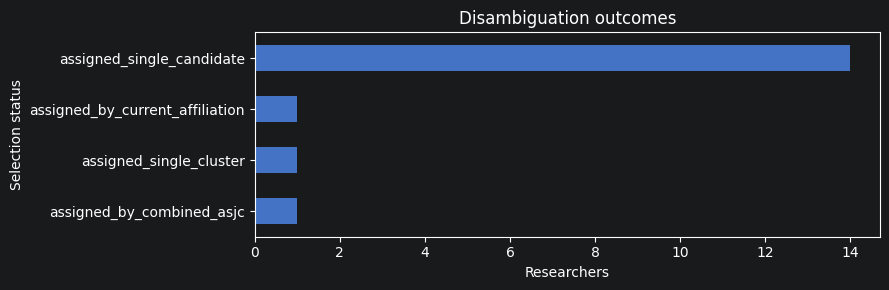

In [17]:
status_counts = selections[SELECTION_STATUS].value_counts().sort_values()
ax = status_counts.plot.barh(figsize=(9, max(3, 0.45 * len(status_counts))), color="#4472C4")
ax.set(title="Disambiguation outcomes", xlabel="Researchers", ylabel="Selection status")
plt.tight_layout()
plt.show()

## 5. Pairwise decisions

Pair decisions describe the evidence-weighted relationship between candidate profiles. The chart is descriptive only; it does not add or modify a decision threshold.

In [18]:
pair_decisions = result.pair_decisions
pair_columns = [
    column
    for column in (
        RESEARCHER_ID,
        LEFT_AUTHOR_ID,
        RIGHT_AUTHOR_ID,
        DECISION_LABEL,
        RAW_SCORE,
        CONFIDENCE,
    )
    if column in pair_decisions.columns
]
display(
    pair_decisions.loc[:, pair_columns]
    .sort_values([RESEARCHER_ID, RAW_SCORE], ascending=[True, False], kind="stable")
)
if not pair_decisions.empty:
    display(
        pair_decisions[DECISION_LABEL]
        .value_counts(dropna=False)
        .rename_axis("pair_decision")
        .to_frame("pair_count")
    )

,sc_id,left_author_id,right_author_id,label,raw_score,confidence
1,990001,990000001,990000002,same_author,28.5,0.999
0,990001,990000001,990000003,distinct,6.0,0.818
2,990001,990000003,990000002,distinct,6.0,0.818
3,990011,990000012,990000019,same_author,12.0,0.953
4,990019,990000020,990000021,distinct,12.0,0.953


,pair_count
pair_decision,
distinct,3
same_author,2


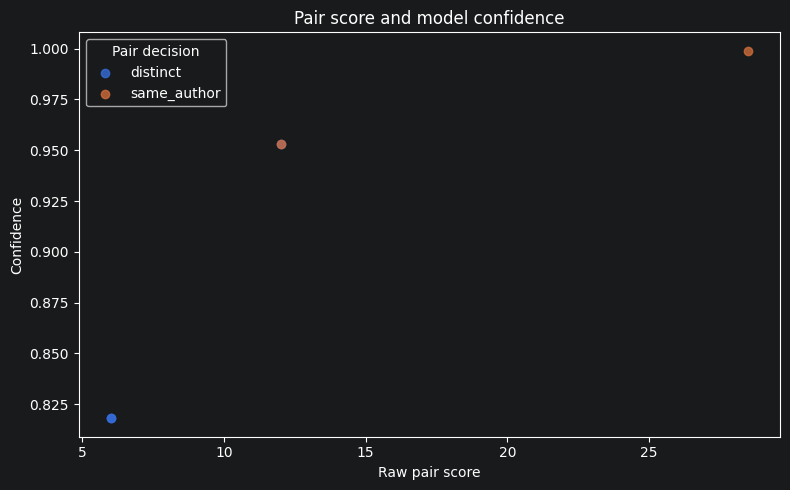

In [19]:
if not pair_decisions.empty and RAW_SCORE in pair_decisions and CONFIDENCE in pair_decisions:
    fig, ax = plt.subplots(figsize=(8, 5))
    for decision_label, group in pair_decisions.groupby(DECISION_LABEL, dropna=False):
        ax.scatter(
            group[RAW_SCORE],
            group[CONFIDENCE],
            label=str(decision_label),
            alpha=0.8,
        )
    ax.set(
        title="Pair score and model confidence",
        xlabel="Raw pair score",
        ylabel="Confidence",
    )
    ax.legend(title="Pair decision")
    plt.tight_layout()
    plt.show()
else:
    print("No pairwise comparisons were produced for these inputs.")

## 6. Cluster memberships

A cluster groups candidate profiles that the pairwise process did not classify as distinct. The table retains researcher-local cluster identifiers and the disambiguated cluster identifier.

In [20]:
clusters = result.clusters
cluster_columns = [
    column
    for column in (
        RESEARCHER_ID,
        CLUSTER_ID,
        DISAMBIGUATED_CLUSTER_ID,
        CLUSTER_SIZE,
        AUTHOR_ID,
        "name",
    )
    if column in clusters.columns
]
display(
    clusters.loc[:, cluster_columns]
    .sort_values([RESEARCHER_ID, CLUSTER_ID, AUTHOR_ID], kind="stable")
)
if not clusters.empty:
    cluster_sizes = clusters[[RESEARCHER_ID, CLUSTER_ID, CLUSTER_SIZE]].drop_duplicates()
    display(cluster_sizes[CLUSTER_SIZE].describe().to_frame("cluster_size"))

,sc_id,cluster_id,disambiguated_cluster_id,cluster_size,author_id,name
1,990001,1,990000001,2,990000001,"Mustermann, Max"
0,990001,1,990000001,2,990000002,"Mustermann, M."
2,990001,2,990000003,1,990000003,"Mustermann, Max"
7,990002,1,990000004,1,990000004,"Doe, John"
8,990004,1,990000005,1,990000005,"Lovelace, Ada"
9,990005,1,990000006,1,990000006,"Al-Hassan, Noor"
10,990006,1,990000007,1,990000007,"García, Zoë"
11,990007,1,990000008,1,990000008,"Martin, Jean-Luc"
12,990008,1,990000009,1,990000009,"Nguyen, Alice M."
13,990009,1,990000010,1,990000010,"O'Connell, Sami"


,cluster_size
count,19.000000
mean,1.105263
std,0.315302
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,2.000000


## 7. Candidate-cluster selection scores

These diagnostics expose the evidence used to compare possible clusters, including subject-area and affiliation overlaps where available. The complete table is retained in memory as `result.final_author_selection_scores`.

In [21]:
selection_scores = result.final_author_selection_scores
display(selection_scores)
if not selection_scores.empty and "current_affiliation_overlap_count" in selection_scores:
    display(
        selection_scores["current_affiliation_overlap_count"]
        .value_counts()
        .sort_index()
        .rename_axis("current_affiliation_overlap_count")
        .to_frame("candidate_cluster_count")
    )

,cluster_id,disambiguated_cluster_id,cluster_size,author_ids,university_name,university_affiliation_ids,cluster_current_affiliation_ids,current_affiliation_overlap_ids,current_affiliation_overlap_count,researcher_given_name_tokens,cluster_given_name_tokens,researcher_given_name_overlap_tokens,researcher_given_name_overlap_count,researcher_given_name_coverage,article_parent_subject_codes,article_parent_subject_overlap_codes,article_parent_subject_overlap_count,article_parent_subject_coverage,profile_parent_subject_codes,profile_parent_subject_overlap_codes,profile_parent_subject_overlap_count,profile_parent_subject_coverage,cluster_subject_codes,cluster_subject_count,cluster_level_two_subject_codes,exact_overlap_codes,exact_overlap_count,exact_inferred_coverage,exact_specific_overlap_codes,exact_specific_overlap_count,exact_specific_coverage,inferred_code_overlap_codes,inferred_code_overlap_count,inferred_code_coverage,overlap_codes,overlap_count,inferred_coverage,researcher_gender,researcher_gender_source,cluster_gender,cluster_gender_source,gender_compatible,sc_id,history
0,1,990000001,2,"[990000002, 990000001]",Example Technical Institute,[],[9901000],[],0,[max],[max],[max],1,1.0,[1700],[1700],1,1.0,[1700],[1700],1,1.0,[1700],1,[1700],[1712],1,1.0,[1712],1,1.0,[1712],1,1.0,[1700],1,1.0,male,max,male,max,True,990001,{}
1,2,990000003,1,[990000003],Example Technical Institute,[],[9902000],[],0,[max],[max],[max],1,1.0,[2700],[],0,0.0,[2700],[],0,0.0,[2700],1,[2700],[],0,0.0,[],0,0.0,[],0,0.0,[],0,0.0,male,max,male,max,True,990001,{}
2,1,990000019,2,"[990000012, 990000019]",Example Technical Institute,[],"[9901000, 9906000]",[],0,[casey],[casey],[casey],1,1.0,"[1700, 2700]",[1700],1,1.0,"[1700, 2700]",[1700],1,1.0,"[1700, 2700]",2,"[1700, 2700]",[1712],1,1.0,[1712],1,1.0,[1712],1,1.0,[1700],1,1.0,unknown,,unknown,,True,990011,{}
3,1,990000020,1,[990000020],TU Wien,[60018163],[60018163],[60018163],1,[ari],[ari],[ari],1,1.0,[2700],[],0,0.0,[2700],[],0,0.0,[2700],1,[2700],[],0,0.0,[],0,0.0,[],0,0.0,[],0,0.0,unknown,,unknown,,True,990019,{}
4,2,990000021,1,[990000021],TU Wien,[60018163],[9907000],[],0,[ari],[ari],[ari],1,1.0,[1200],[],0,0.0,[1200],[],0,0.0,[1200],1,[1200],[],0,0.0,[],0,0.0,[],0,0.0,[],0,0.0,unknown,,unknown,,True,990019,{}


,candidate_cluster_count
current_affiliation_overlap_count,
0,4
1,1


## 8. Complete per-researcher batch results

The result also retains each batch's prepared candidate frame, pair decisions, clusters, final selection object, and score diagnostics. The report below renders the detailed decision explanation for every researcher batch directly from those in-memory objects; it does not read report files.

In [22]:
for batch in result.batch_results:
    display(Markdown(f"### Researcher {batch.sc_id}"))
    display(Markdown("#### Prepared candidate rows"))
    display(batch.authors)
    display(Markdown("#### Pair decisions"))
    display(batch.decisions)
    display(Markdown("#### Cluster memberships"))
    display(batch.clusters)
    display(Markdown("#### Candidate-cluster scores"))
    display(batch.final_selection_scores)
    display(Markdown("#### Final selection and narrative"))
    display(batch.final_selection)
    display(Markdown("```text\n" + render_text_report(
        batch.decisions,
        batch.clusters,
        batch.final_selection,
        batch.final_selection_scores,
    ).rstrip() + "\n```"))

### Researcher 990001

#### Prepared candidate rows

,sc_id,person_title,person_fullname,organization,university_name,inferred_asjc_codes,inferred_asjc_labels,is_alternative,person_surname,person_name,initials,author_id,priority,researcher_name,eid,name,indexed_name,given_name,surname,publication_range,name_variants,subject_areas,historical_identifier,affiliation_id,affiliation_id_parent,affiliation_name,affiliation_id_parent_chatgpt,affiliation_id_parent_splink_chatgpt,affiliation_ids_current,author_name,synthetic_record,raw_record,canonical_surname,canonical_given_name,canonical_name,canonical_indexed_name,canonical_initials,publication_range_parsed,publication_start,publication_end,name_variants_parsed,subject_areas_parsed,subject_area_labels
0,990001,,Max Mustermann,Example Faculty of Computing,Example Technical Institute,1712,Software,,Mustermann,Max,False,990000001,1,"mustermann, max",SYN-PUB-001,"Mustermann, Max","Mustermann, Max",Max,Mustermann,"{2018,2024}","[{""indexed_name"":""Mustermann, Max"",""initials"":""M"",""surname"":""Mustermann"",""given_name"":""Max"",""doc...","[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",,9901000,9901000,Example Technical Institute,,,[9901000],"mustermann, max",True,"{'sc_id': '990001', 'person_title': '', 'person_fullname': 'Max Mustermann', 'organization': 'Ex...",mustermann,max,"mustermann, max",mustermann max,M,"PublicationRange(start=2018, end=2024)",2018.0,2024.0,"[NameVariant(indexed_name='Mustermann, Max', initials='M', surname='Mustermann', given_name='Max...","[SubjectArea(area='Software', abbreviation='COMP', code=1712)]",[COMP]
1,990001,,Max Mustermann,Example Faculty of Computing,Example Technical Institute,1712,Software,,Mustermann,Max,False,990000003,1,"mustermann, max",SYN-PUB-003,"Mustermann, Max","Mustermann, Max",Max,Mustermann,"{1986,1992}",[],"[{""area"":""General Medicine"",""abbreviation"":""MEDI"",""code"":2700}]",,9902000,9902000,Example Medical Institute,,,[9902000],"mustermann, max",True,"{'sc_id': '990001', 'person_title': '', 'person_fullname': 'Max Mustermann', 'organization': 'Ex...",mustermann,max,"mustermann, max",mustermann max,M,"PublicationRange(start=1986, end=1992)",1986.0,1992.0,[],"[SubjectArea(area='General Medicine', abbreviation='MEDI', code=2700)]",[MEDI]
2,990001,,Max Mustermann,Example Faculty of Computing,Example Technical Institute,1712,Software,,Mustermann,Max,True,990000002,4,"mustermann, max",SYN-PUB-002,"Mustermann, M.",Mustermann M,M.,Mustermann,"{2019,2024}","[{""indexed_name"":""Mustermann, Max"",""initials"":""M"",""surname"":""Mustermann"",""given_name"":""Max"",""doc...","[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",,9901000,9901000,Example Technical Institute,,,[9901000],"mustermann, m",True,"{'sc_id': '990001', 'person_title': '', 'person_fullname': 'Max Mustermann', 'organization': 'Ex...",mustermann,m,"mustermann, m",mustermann m,M,"PublicationRange(start=2019, end=2024)",2019.0,2024.0,"[NameVariant(indexed_name='Mustermann, Max', initials='M', surname='Mustermann', given_name='Max...","[SubjectArea(area='Software', abbreviation='COMP', code=1712)]",[COMP]


#### Pair decisions

,left_row_id,right_row_id,left_author_id,right_author_id,left_name,right_name,left_canonical_name,right_canonical_name,left_canonical_surname,right_canonical_surname,left_canonical_given_name,right_canonical_given_name,left_canonical_indexed_name,right_canonical_indexed_name,left_canonical_initials,right_canonical_initials,raw_score,confidence,label,components
0,,,990000001,990000003,"Mustermann, Max","Mustermann, Max","mustermann, max","mustermann, max",mustermann,mustermann,max,max,mustermann max,mustermann max,M,M,6.0,0.818,distinct,"[{'label': 'shared_first_name_nongeneral', 'weight': 6.0, 'reason': 'shared first-name evidence:..."
1,,,990000001,990000002,"Mustermann, Max","Mustermann, M.","mustermann, max","mustermann, m",mustermann,mustermann,max,m,mustermann max,mustermann m,M,M,28.5,0.999,same_author,"[{'label': 'shared_first_name_nongeneral', 'weight': 6.0, 'reason': 'shared first-name evidence:..."
2,,,990000003,990000002,"Mustermann, Max","Mustermann, M.","mustermann, max","mustermann, m",mustermann,mustermann,max,m,mustermann max,mustermann m,M,M,6.0,0.818,distinct,"[{'label': 'shared_first_name_nongeneral', 'weight': 6.0, 'reason': 'shared first-name evidence:..."


#### Cluster memberships

... (194 outputs left out)

""


#### Final selection and narrative

FinalAuthorSelection(sc_id='990018', status='assigned_single_candidate', selected_cluster_id=1, selected_disambiguated_cluster_id='990000018', selected_author_ids=['990000018'], possible_clusters=[['990000018']], inferred_asjc_codes=[3300], scopus_asjc_codes=[3300], inferred_asjc_labels=['Social Sciences'], reason='only one candidate author exists for this sc_id; disambiguation not required')

```text
Author Name Disambiguation
============================

sc_id: 990018

Pair comparisons: 0
Identity clusters: 1

Pairwise evidence
-----------------
Clusters
--------
Cluster 1: 1 record(s) | disambiguated_cluster_id=990000018 | selected=yes
  - Kim, Jordan | author_id=990000018 | selected=yes | indexed=Kim, Jordan | years=2017.0-2024.0 | areas=SOCI

Final Selection
---------------
status=assigned_single_candidate
selected_disambiguated_cluster_id=990000018
selected_author_ids=['990000018']
inferred_asjc_codes=[3300]
target_subject_areas=[3300 (General Social Sciences)]
target_level2_subject_areas=[3300 (General Social Sciences)]
inferred_asjc_labels=['Social Sciences']
reason=only one candidate author exists for this sc_id; disambiguation not required
```

## Summary

The notebook reads the synthetic configuration, validates the configured inputs, invokes `compute_name_disambiguation`, and presents every component of its returned result. It does not call the persistence API or write disambiguation artifacts. If the configured matcher artifact is absent, dependency preparation may run the matching producer; external inputs must already exist. Existing generated artifacts are not checked for freshness.